<a href="https://colab.research.google.com/github/jvbrandao18/mestrado/blob/main/Aula_05_Process_Mining_Completo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 5 — Machine Learning aplicado ao Process Mining
**PDMPI | Lecture 05 | Atividade da página 80**  
**Fonte:** `project_process_mining_event_log.csv` • **Unidade de análise do modelo:** um projeto (`case_id`)

**Objetivo:** investigar as características dos processos e prever `case_outcome` a partir de atributos conhecidos na abertura de cada projeto. Este notebook adapta os exemplos de Naive Bayes, SVM, MLP e validação cruzada das páginas 65–78 do PDF, sem copiar as variáveis da base de apartamentos.

**Roteiro:** (1) carregar e explorar; (2) análise univariada; (3) análise multivariada; (4) justificar X e y; (5) comparar KNN, árvore, Naive Bayes, SVM e MLP com validação cruzada estratificada; (6) avaliação e conclusão.

## 0. Preparação e bibliotecas
No Google Colab, carregue o CSV no painel **Arquivos** ou execute a célula de upload quando solicitado. O arquivo original enviado nesta conversa se chama `project_process_mining_event_log(1).csv`. Ao reiniciar o ambiente do Colab, será necessário reenviá-lo.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 1. Carregar e explorar os dados
A base contém **eventos**, não casos independentes. Verificamos número de eventos e de casos, variáveis, tipos e valores ausentes. Datas são convertidas para `datetime` somente para facilitar a inspeção; **não** entram automaticamente no modelo.

In [2]:
paths = [Path("project_process_mining_event_log.csv"), Path("project_process_mining_event_log(1).csv"), Path("/mnt/data/project_process_mining_event_log(1).csv")]
path = next((q for q in paths if q.exists()), None)
if path is None:
    try:
        from google.colab import files
        print("Envie o arquivo project_process_mining_event_log.csv")
        uploaded = files.upload()
        path = Path(next(iter(uploaded)))
    except ImportError as exc:
        raise FileNotFoundError("Coloque o CSV na mesma pasta do notebook e execute novamente.") from exc

df = pd.read_csv(path)
for column in ["start_timestamp", "complete_timestamp"]:
    df[column] = pd.to_datetime(df[column], errors="coerce")
print(f"Arquivo: {path.name} | Eventos: {len(df):,} | Colunas: {df.shape[1]} | Casos: {df.case_id.nunique():,}")
display(df.head())
df.info()
assert df.case_id.notna().all(), "Existem eventos sem case_id"
assert df.groupby("case_id").case_outcome.nunique(dropna=False).eq(1).all(), "case_outcome não é constante em alguns casos"

Envie o arquivo project_process_mining_event_log.csv


Saving project_process_mining_event_log.csv to project_process_mining_event_log.csv
Arquivo: project_process_mining_event_log.csv | Eventos: 23,388 | Colunas: 22 | Casos: 1,200


,case_id,event_id,event_sequence,activity,start_timestamp,complete_timestamp,processing_time_hours,resource,role,department,project_type,priority,region,estimated_amount_brl,procurement_required,status,rework_flag,notes,source_system,waiting_time_from_previous_hours,case_duration_days,case_outcome
0,PRJ-2026-0001,PRJ-2026-0001-E01,1,Register Project Request,2026-01-26 08:00:00,2026-01-26 08:31:59,0.53,Ana,Requester,Manufacturing,Maintenance Upgrade,Low,Araucária,23300.04,True,Completed,False,NaN,PMO Portal,0.00,38.1,Completed On Time
1,PRJ-2026-0001,PRJ-2026-0001-E02,2,Initial Completeness Check,2026-01-26 16:09:19,2026-01-27 08:32:48,1.39,Lucas,PMO Analyst,Manufacturing,Maintenance Upgrade,Low,Araucária,23300.04,True,Completed,False,NaN,PMO Portal,7.62,38.1,Completed On Time
2,PRJ-2026-0001,PRJ-2026-0001-E03,3,Technical Feasibility Review,2026-01-27 08:32:48,2026-01-27 13:29:16,4.94,Paula,Engineer,Manufacturing,Maintenance Upgrade,Low,Araucária,23300.04,True,Completed,False,NaN,PMO Portal,0.00,38.1,Completed On Time
3,PRJ-2026-0001,PRJ-2026-0001-E04,4,Estimate Budget,2026-01-28 13:29:16,2026-01-28 15:44:30,2.25,Otavio,Engineer,Manufacturing,Maintenance Upgrade,Low,Araucária,23300.04,True,Completed,False,NaN,PMO Portal,24.00,38.1,Completed On Time
4,PRJ-2026-0001,PRJ-2026-0001-E05,5,Budget Approval,2026-02-02 15:44:30,2026-02-03 09:46:01,3.03,Sofia,Finance,Manufacturing,Maintenance Upgrade,Low,Araucária,23300.04,True,Completed,False,NaN,ERP,120.00,38.1,Completed On Time


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23388 entries, 0 to 23387
Data columns (total 22 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   case_id                           23388 non-null  object        
 1   event_id                          23388 non-null  object        
 2   event_sequence                    23388 non-null  int64         
 3   activity                          23388 non-null  object        
 4   start_timestamp                   23388 non-null  datetime64[ns]
 5   complete_timestamp                23388 non-null  datetime64[ns]
 6   processing_time_hours             22219 non-null  float64       
 7   resource                          22219 non-null  object        
 8   role                              22686 non-null  object        
 9   department                        23388 non-null  object        
 10  project_type                      22690 non-nu

In [3]:
faltantes = pd.DataFrame({"Ausentes": df.isna().sum(), "Percentual (%)": (100*df.isna().mean()).round(2)})
display(faltantes.sort_values("Percentual (%)", ascending=False))
display(df.describe(include="number").T)
print("Distribuição de eventos por caso:")
display(df.groupby("case_id").size().describe())

,Ausentes,Percentual (%)
notes,19621,83.89
waiting_time_from_previous_hours,1331,5.69
resource,1169,5.00
processing_time_hours,1169,5.00
estimated_amount_brl,1159,4.96
priority,943,4.03
source_system,936,4.00
case_duration_days,917,3.92
role,702,3.00
project_type,698,2.98


,count,mean,std,min,25%,50%,75%,max
event_sequence,23388.0,10.703480,6.243511,1.00,5.00,10.00,16.00,32.00
processing_time_hours,22219.0,2.089785,2.587343,0.11,0.69,1.24,2.49,49.16
estimated_amount_brl,22229.0,51842.081303,47806.481023,2107.01,21858.64,38203.48,65781.39,450000.00
waiting_time_from_previous_hours,22057.0,62.125620,85.038226,0.00,7.93,48.00,72.00,791.64
case_duration_days,22471.0,58.319427,15.570894,5.19,49.08,58.71,68.96,104.85


Distribuição de eventos por caso:


,0
count,1200.00000
mean,19.49000
std,4.22924
min,6.00000
25%,18.00000
50%,20.00000
75%,22.00000
max,32.00000


## 2. Análise univariada
Histogramas examinam assimetria; boxplots destacam valores extremos; frequências descrevem variáveis categóricas. Valores extremos **não são eliminados automaticamente**: em processos, podem representar gargalos reais.

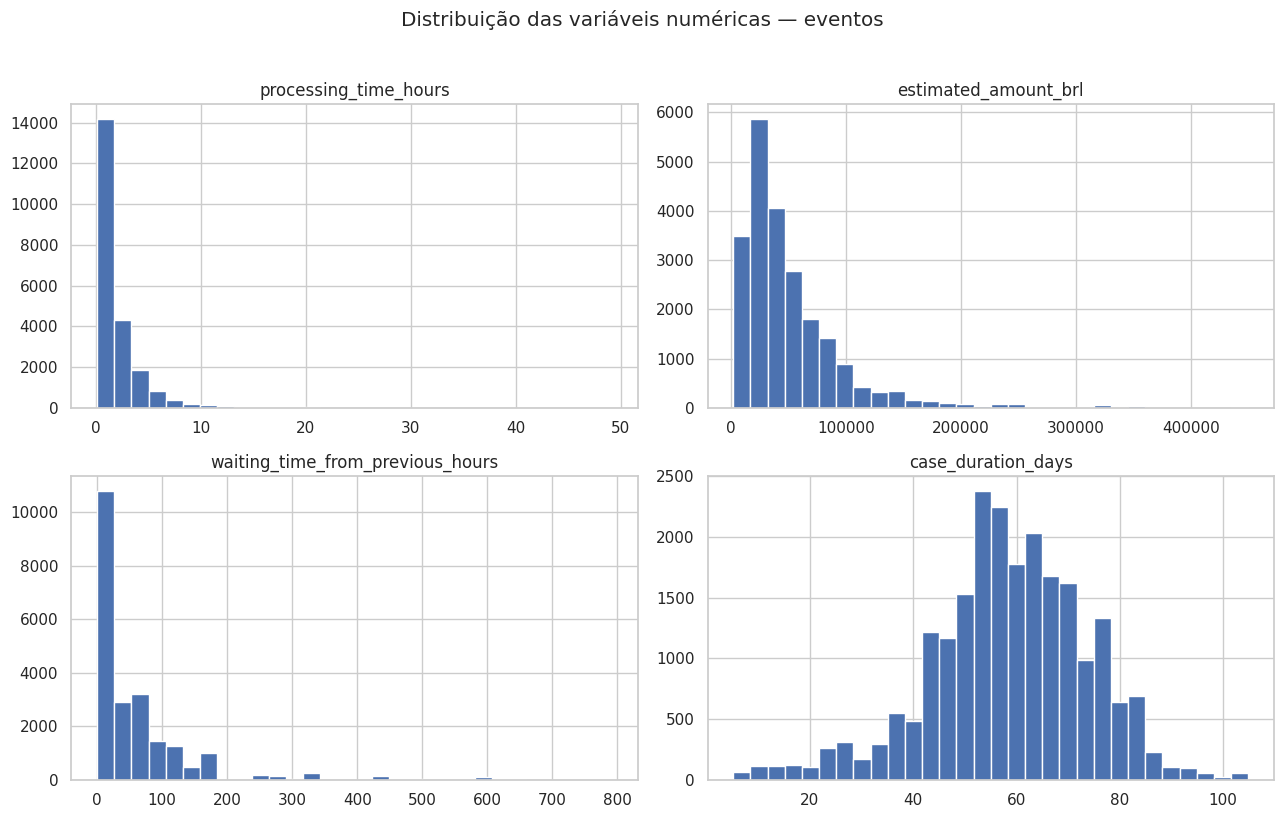

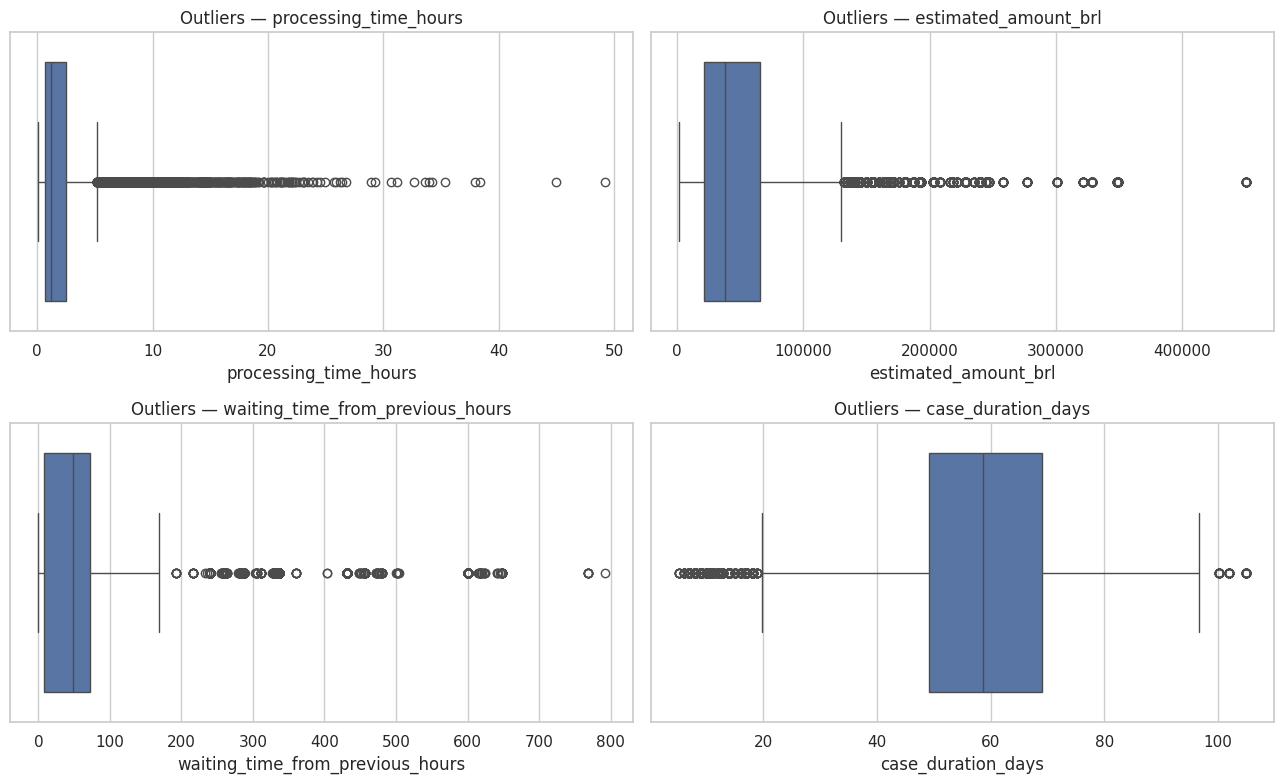

In [4]:
num_evento = ["processing_time_hours", "estimated_amount_brl", "waiting_time_from_previous_hours", "case_duration_days"]
df[num_evento].hist(bins=30, figsize=(13, 8))
plt.suptitle("Distribuição das variáveis numéricas — eventos", y=1.02)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, num_evento):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Outliers — {col}")
plt.tight_layout(); plt.show()

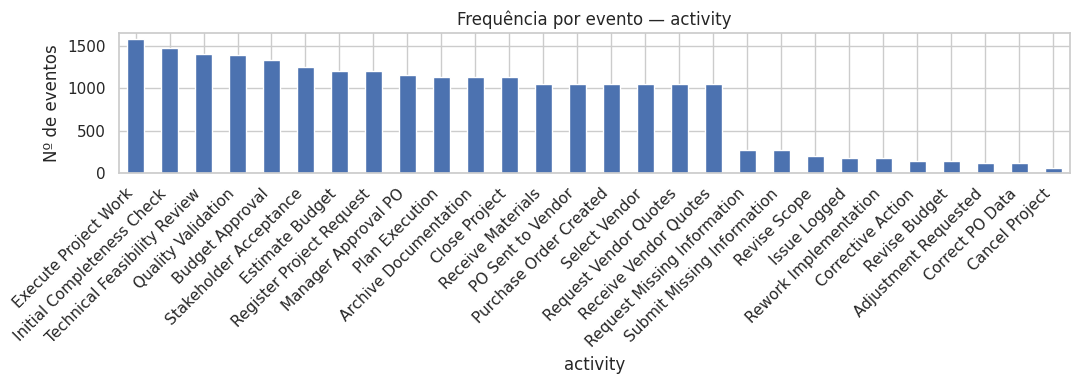

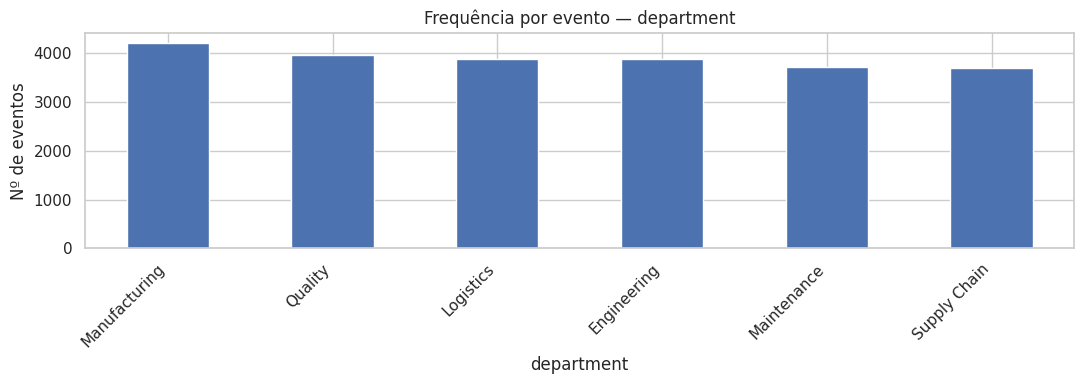

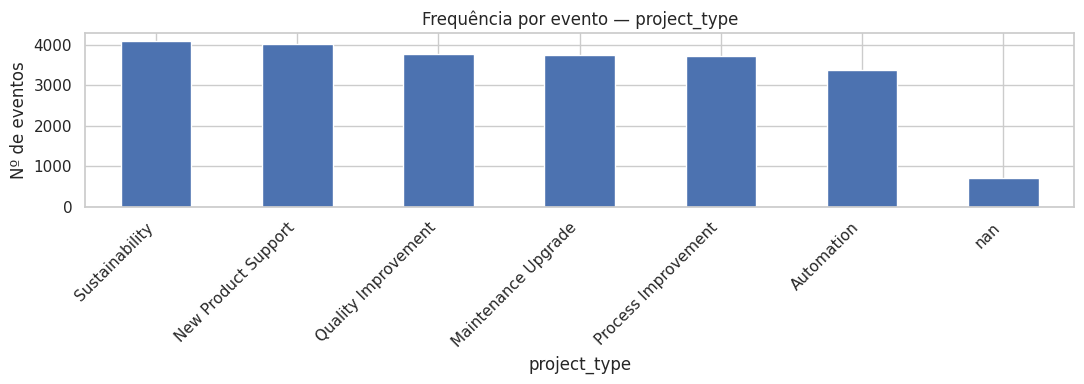

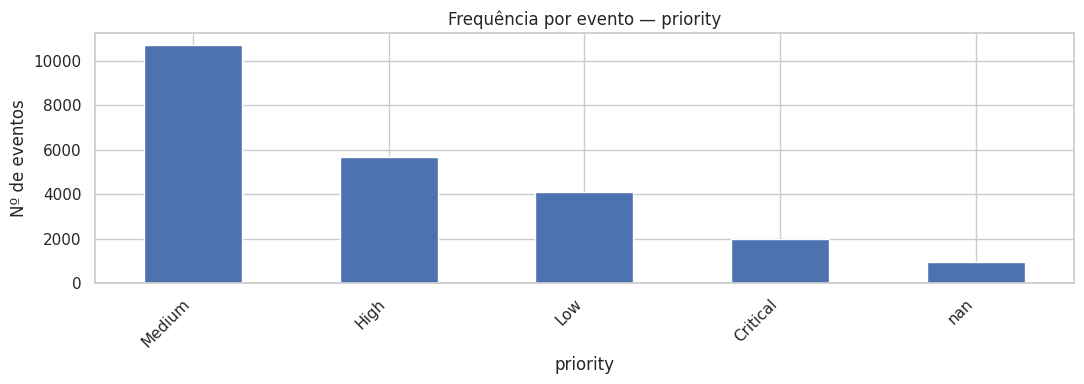

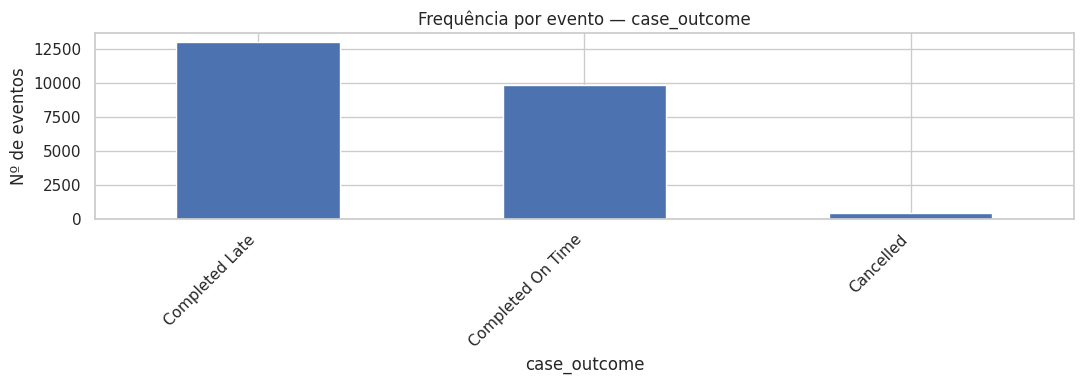

In [5]:
for col in ["activity", "department", "project_type", "priority", "case_outcome"]:
    fig, ax = plt.subplots(figsize=(11, 4))
    df[col].value_counts(dropna=False).plot.bar(ax=ax)
    ax.set(title=f"Frequência por evento — {col}", ylabel="Nº de eventos", xlabel=col)
    plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

**Atenção à unidade:** o gráfico de `case_outcome` por evento super-representa processos com mais eventos. Para inferências sobre resultados de projetos, construímos abaixo **uma linha por caso**, sempre usando o primeiro evento real. `groupby().first()` seria inadequado porque seleciona a primeira informação **não nula** de cada coluna, eventualmente de eventos posteriores.

Casos: 1200 | Sequência inicial: {1: 1200}


,case_id,event_sequence,activity,priority,department,case_outcome
0,PRJ-2026-0001,1,Register Project Request,Low,Manufacturing,Completed On Time
18,PRJ-2026-0002,1,Register Project Request,High,Manufacturing,Completed Late
40,PRJ-2026-0003,1,Register Project Request,Medium,Supply Chain,Completed On Time
58,PRJ-2026-0004,1,Register Project Request,Medium,Engineering,Completed On Time
79,PRJ-2026-0005,1,Register Project Request,High,Supply Chain,Completed Late


,Casos,Percentual (%)
case_outcome,,
Completed Late,608,50.67
Completed On Time,532,44.33
Cancelled,60,5.00


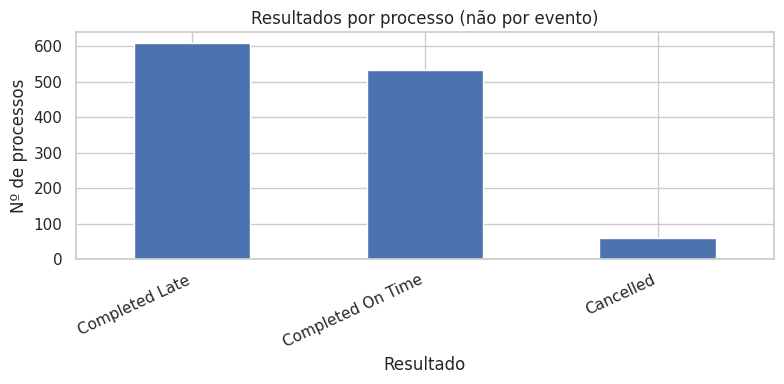

In [6]:
df_cases = (df.sort_values(["case_id", "event_sequence", "start_timestamp"])
            .drop_duplicates(subset="case_id", keep="first").copy())
assert len(df_cases) == df.case_id.nunique()
print("Casos:", len(df_cases), "| Sequência inicial:", df_cases.event_sequence.value_counts().to_dict())
display(df_cases[["case_id", "event_sequence", "activity", "priority", "department", "case_outcome"]].head())
outcomes = df_cases.case_outcome.value_counts()
display(pd.DataFrame({"Casos": outcomes, "Percentual (%)": (outcomes/len(df_cases)*100).round(2)}))
ax = outcomes.plot.bar(figsize=(8,4), title="Resultados por processo (não por evento)")
ax.set(xlabel="Resultado", ylabel="Nº de processos"); plt.xticks(rotation=25, ha="right")
plt.tight_layout(); plt.show()

## 3. Análise multivariada
Examinamos correlações numéricas **no nível de evento** e associações entre categorias e resultados **no nível de caso**. Correlação não implica causalidade. Variáveis posteriores ao início do caso podem ser analisadas descritivamente, mas não entrarão na previsão inicial.

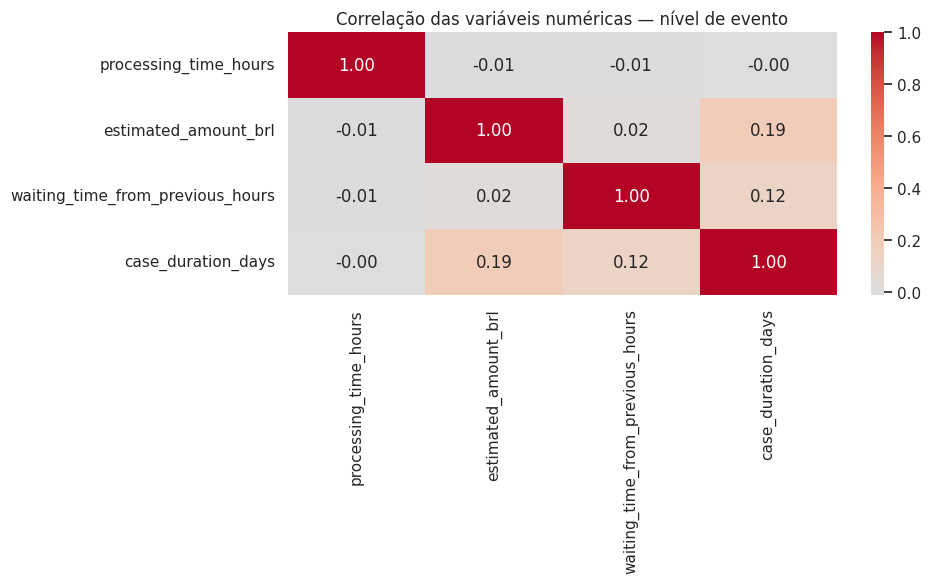

Nota: case_duration_days é repetida entre eventos do mesmo caso; interpretar com cautela.


In [7]:
corr = df[num_evento].corr()
plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação das variáveis numéricas — nível de evento")
plt.tight_layout(); plt.show()
print("Nota: case_duration_days é repetida entre eventos do mesmo caso; interpretar com cautela.")

Resultados por priority (% de casos em cada categoria):


case_outcome,Cancelled,Completed Late,Completed On Time
priority,,,
Critical,2.00,72.00,26.00
High,3.50,68.88,27.62
Low,6.54,42.52,50.93
Medium,5.98,40.04,53.99
Não informado,2.08,56.25,41.67


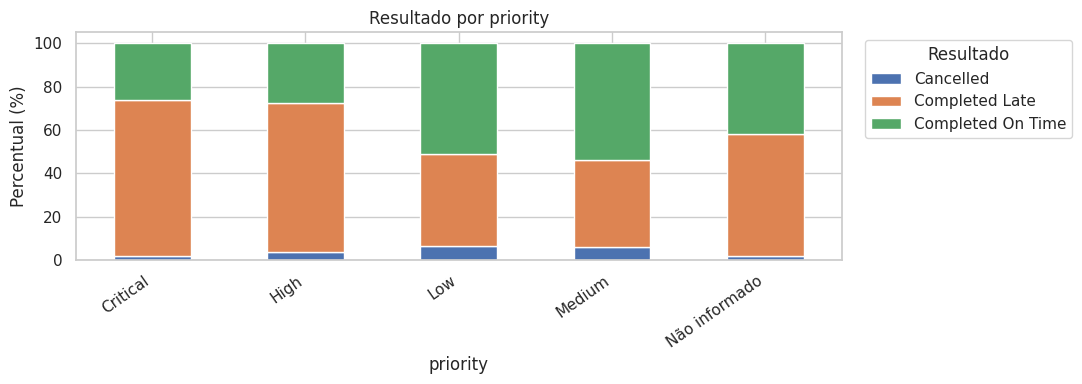

Resultados por department (% de casos em cada categoria):


case_outcome,Cancelled,Completed Late,Completed On Time
department,,,
Engineering,3.43,50.00,46.57
Logistics,5.05,50.51,44.44
Maintenance,7.33,52.36,40.31
Manufacturing,5.21,53.08,41.71
Quality,3.45,46.31,50.25
Supply Chain,5.70,51.81,42.49


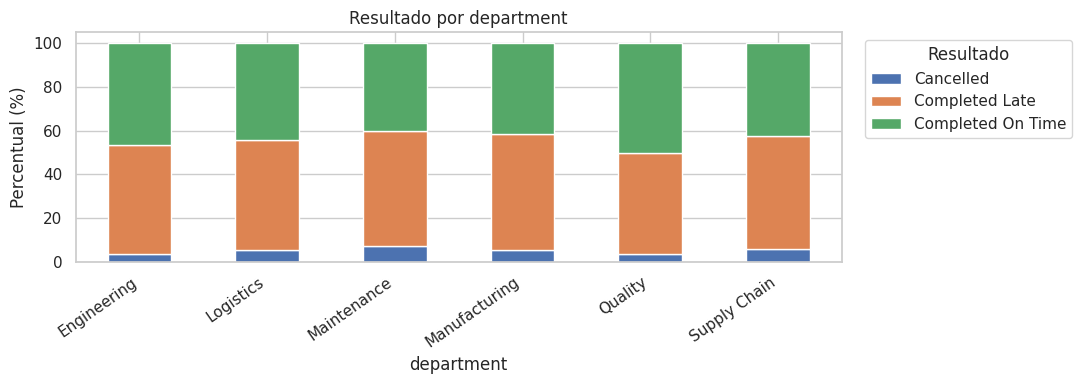

Resultados por project_type (% de casos em cada categoria):


case_outcome,Cancelled,Completed Late,Completed On Time
project_type,,,
Automation,5.26,61.40,33.33
Maintenance Upgrade,5.21,43.23,51.56
New Product Support,5.39,55.88,38.73
Não informado,8.33,47.22,44.44
Process Improvement,4.19,50.26,45.55
Quality Improvement,4.66,53.37,41.97
Sustainability,4.69,42.25,53.05


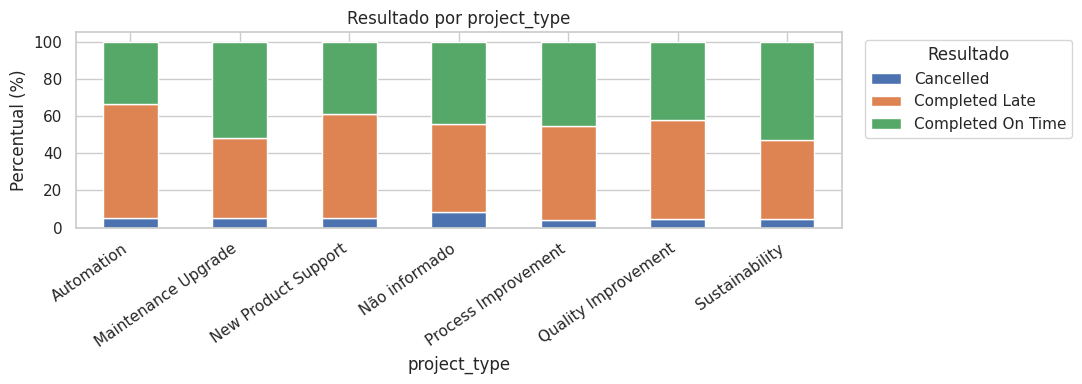

In [8]:
for col in ["priority", "department", "project_type"]:
    tabela = pd.crosstab(df_cases[col].fillna("Não informado"), df_cases["case_outcome"], normalize="index")*100
    print(f"Resultados por {col} (% de casos em cada categoria):")
    display(tabela.round(2))
    ax = tabela.plot.bar(stacked=True, figsize=(11, 4))
    ax.set(title=f"Resultado por {col}", xlabel=col, ylabel="Percentual (%)")
    plt.xticks(rotation=35, ha="right"); plt.legend(title="Resultado", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout(); plt.show()

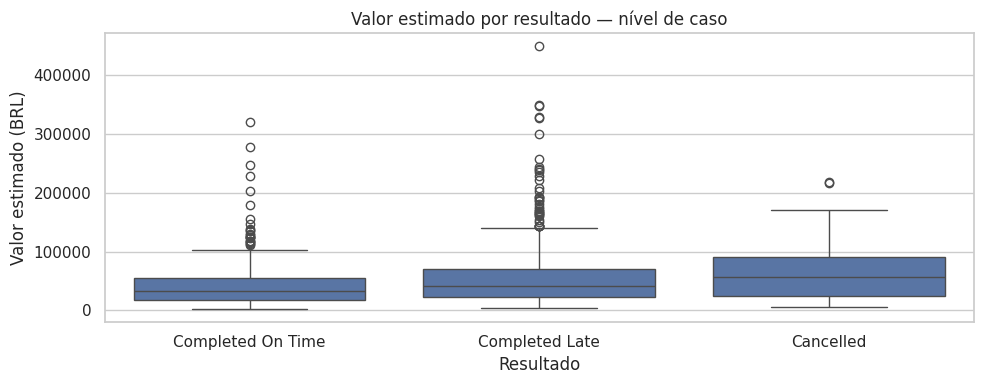

In [9]:
# Valor estimado é atributo disponível na abertura (quando preenchido)
fig, ax = plt.subplots(figsize=(10,4))
sns.boxplot(data=df_cases, x="case_outcome", y="estimated_amount_brl", ax=ax)
ax.set(title="Valor estimado por resultado — nível de caso", xlabel="Resultado", ylabel="Valor estimado (BRL)")
plt.tight_layout(); plt.show()

## 4. Definição de X e y — justificativa e prevenção de leakage
**Problema:** classificação multiclasse do resultado futuro do projeto (`case_outcome`: no prazo / atrasado / cancelado).

**X:** `priority` (forte associação observada com atrasos), `department` (diferenças entre áreas), `project_type` (natureza), `region` (localização), `estimated_amount_brl` (escala financeira) e `procurement_required` (necessidade de compras). São características plausivelmente conhecidas na abertura, **assumindo** que não foram atualizadas retroativamente.

**Excluídas:** IDs, `status`, `case_duration_days`, esperas acumuladas e eventos posteriores — apresentam risco de identificadores espúrios ou informações futuras. O evento inicial foi utilizado apenas para extrair atributos do caso; `case_outcome` é o rótulo final.

**Faltantes:** imputação somente nos folds de treinamento. **Categóricas:** one-hot. **Valor estimado:** mediana e escala. Como cada linha é um caso único, a validação cruzada não distribui eventos do mesmo caso entre treino e validação.

In [10]:
features = ["priority", "department", "project_type", "region", "estimated_amount_brl", "procurement_required"]
X = df_cases[features].copy()
y = df_cases["case_outcome"].copy()
print("X:", X.shape, "| y:", y.shape)
display(X.isna().sum().to_frame("Valores ausentes"))
display(y.value_counts())
assert len(X)==len(y)==1200
numeric_features = ["estimated_amount_brl"]
categorical_features = ["priority", "department", "project_type", "region", "procurement_required"]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical_features)
], sparse_threshold=0)
print("Pré-processamento definido dentro dos pipelines (sem vazamento entre folds).")

X: (1200, 6) | y: (1200,)


,Valores ausentes
priority,48
department,0
project_type,36
region,36
estimated_amount_brl,60
procurement_required,0


,count
case_outcome,
Completed Late,608
Completed On Time,532
Cancelled,60


Pré-processamento definido dentro dos pipelines (sem vazamento entre folds).


## 5. K-Fold estratificado: treinar e comparar cinco modelos
Adaptação das páginas **74–78**: `StratifiedKFold` preserva aproximadamente as proporções das três classes; `cross_validate` informa acurácia e F1 macro. O `Pipeline` ajusta imputação e transformação novamente em cada fold. Incluímos um **baseline** que sempre prevê a classe mais frequente. Os hiperparâmetros abaixo são fixados para permitir reprodução, não otimizados.

In [11]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "SVM (RBF)": SVC(kernel="rbf", C=1, random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42),
    "Baseline (mais frequente)": DummyClassifier(strategy="most_frequent")
}
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
pipelines = {name: Pipeline([("preprocessor", preprocessor), ("model", model)]) for name,model in models.items()}
rows=[]
for name,pipe in pipelines.items():
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        scores = cross_validate(pipe, X, y, cv=cv, scoring={"accuracy":"accuracy", "f1_macro":"f1_macro"}, n_jobs=1)
    rows.append({"Modelo": name, "Acurácia média": scores["test_accuracy"].mean(), "Desvio padrão": scores["test_accuracy"].std(), "F1 macro": scores["test_f1_macro"].mean(), "F1 desvio": scores["test_f1_macro"].std()})
    print(f"{name:<26} acc={scores['test_accuracy'].mean():.3f} ±{scores['test_accuracy'].std():.3f}; F1-macro={scores['test_f1_macro'].mean():.3f}")
results_df = pd.DataFrame(rows).sort_values("F1 macro", ascending=False).reset_index(drop=True)
display(results_df.round(4))

KNN                        acc=0.545 ±0.016; F1-macro=0.388
Decision Tree              acc=0.510 ±0.020; F1-macro=0.366
Naive Bayes                acc=0.587 ±0.018; F1-macro=0.377
SVM (RBF)                  acc=0.585 ±0.023; F1-macro=0.399
MLP                        acc=0.512 ±0.019; F1-macro=0.368
Baseline (mais frequente)  acc=0.507 ±0.000; F1-macro=0.224


,Modelo,Acurácia média,Desvio padrão,F1 macro,F1 desvio
0,SVM (RBF),0.5850,0.0227,0.3987,0.0150
1,KNN,0.5450,0.0159,0.3875,0.0200
2,Naive Bayes,0.5867,0.0183,0.3769,0.0079
3,MLP,0.5125,0.0191,0.3675,0.0090
4,Decision Tree,0.5100,0.0196,0.3664,0.0204
5,Baseline (mais frequente),0.5067,0.0000,0.2242,0.0000


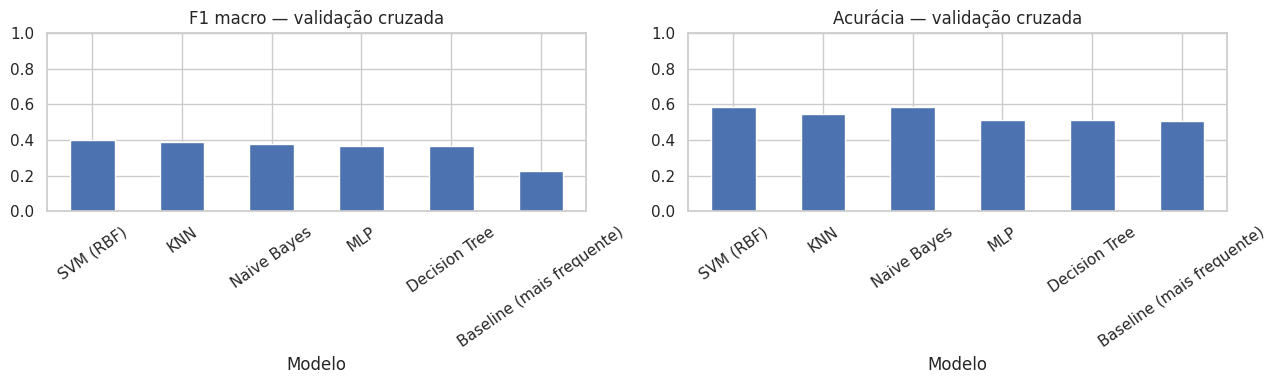

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
results_df.plot.bar(x="Modelo", y="F1 macro", ax=axes[0], legend=False)
results_df.plot.bar(x="Modelo", y="Acurácia média", ax=axes[1], legend=False)
for ax in axes:
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=35)
axes[0].set_title("F1 macro — validação cruzada")
axes[1].set_title("Acurácia — validação cruzada")
plt.tight_layout(); plt.show()

## 6. Diagnóstico de classificação (SVM) e balanceamento — complemento
Adaptação das páginas **65–66** (`classification_report` e matriz de confusão) e **68–69** (SVM RBF). `cross_val_predict` gera previsões fora do fold de treino para cada processo; não são previsões feitas pelo modelo ajustado em todos os dados. A matriz mostra as classes que o modelo confunde.


 SVM (RBF)
                   precision    recall  f1-score   support

        Cancelled       0.00      0.00      0.00        60
   Completed Late       0.60      0.64      0.62       608
Completed On Time       0.56      0.58      0.57       532

         accuracy                           0.58      1200
        macro avg       0.39      0.41      0.40      1200
     weighted avg       0.56      0.58      0.57      1200



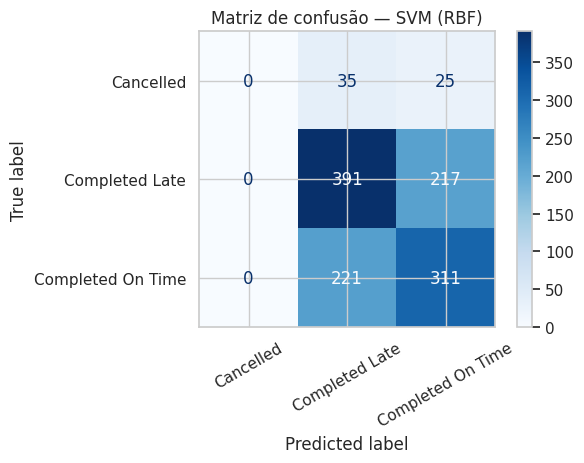


 SVM (RBF) balanceado
                   precision    recall  f1-score   support

        Cancelled       0.04      0.13      0.06        60
   Completed Late       0.67      0.47      0.55       608
Completed On Time       0.56      0.61      0.58       532

         accuracy                           0.51      1200
        macro avg       0.43      0.40      0.40      1200
     weighted avg       0.59      0.51      0.54      1200



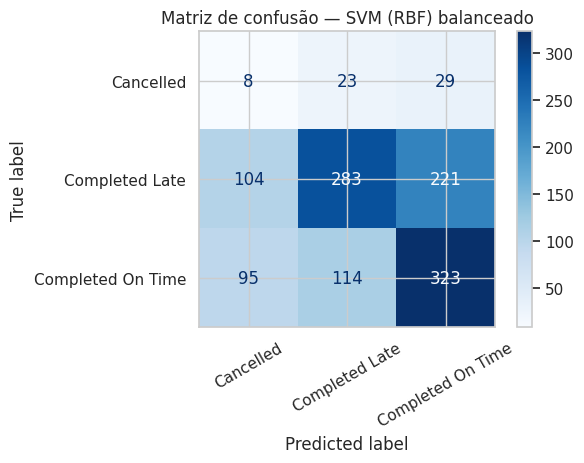

In [13]:
labels = ["Cancelled", "Completed Late", "Completed On Time"]
for name,pipe in [("SVM (RBF)", pipelines["SVM (RBF)"]),
                   ("SVM (RBF) balanceado", Pipeline([("preprocessor", preprocessor), ("model", SVC(kernel="rbf", C=1, class_weight="balanced", random_state=42))]))]:
    pred = cross_val_predict(pipe, X, y, cv=cv)
    print("\n", name)
    print(classification_report(y, pred, labels=labels, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y, pred, labels=labels, cmap="Blues", xticks_rotation=30)
    plt.title(f"Matriz de confusão — {name}")
    plt.tight_layout(); plt.show()

## 7. Curva de perda do MLP — complemento das páginas 71–72
A curva `loss_curve_` descreve o erro durante o **treinamento**. Queda/estabilização não comprova generalização: essa comparação cabe às métricas de validação cruzada.

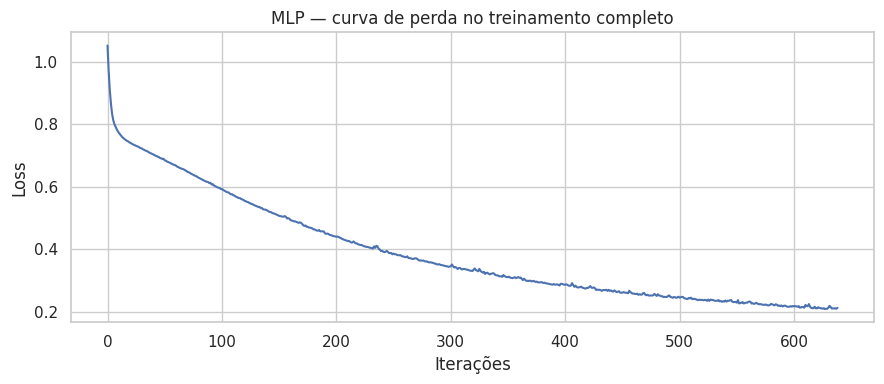

Iterações: 639 | perda final: 0.2125


In [14]:
mlp_full = pipelines["MLP"].fit(X,y)
mlp_model = mlp_full.named_steps["model"]
plt.figure(figsize=(9,4))
plt.plot(mlp_model.loss_curve_)
plt.title("MLP — curva de perda no treinamento completo")
plt.xlabel("Iterações"); plt.ylabel("Loss"); plt.tight_layout(); plt.show()
print("Iterações:", mlp_model.n_iter_, "| perda final:", round(mlp_model.loss_, 4))

## 8. Conclusão do experimento
A análise exploratória evidenciou assimetria e valores extremos em durações, esperas e valores estimados. As variáveis de prioridade e departamento apresentaram diferenças descritivas entre resultados; isso **não prova causalidade**.

Foram testados KNN, Decision Tree, Gaussian Naive Bayes, SVM RBF e MLP por **validação cruzada estratificada de quatro folds**, com pré-processamento aplicado apenas ao fold de treinamento. O `case_outcome` foi previsto por características do **primeiro evento de cada caso**, sem empregar duração final, status final ou esperas posteriores.

A tabela acima apresenta o desempenho real e inclui um baseline. O F1 macro é especialmente importante porque `Cancelled` corresponde a apenas **5%** dos casos. A matriz de confusão revela se algum modelo negligencia essa classe. Mesmo o melhor modelo da comparação pode ser **inadequado para decisão operacional**, caso apresente desempenho insuficiente na classe minoritária.

**Critério de escolha:** selecionar o maior **F1 macro médio** entre os cinco modelos solicitados; usar acurácia e desvio-padrão como contexto. Se a diferença for pequena ou inferior ao baseline, registrar a limitação. Ajustes de hiperparâmetros, novos atributos disponíveis no momento da previsão e avaliação em um conjunto independente seriam etapas futuras, não exigências da página 80.

In [15]:
exigidos = results_df[results_df["Modelo"] != "Baseline (mais frequente)"]
best = exigidos.sort_values("F1 macro", ascending=False).iloc[0]
baseline = results_df.loc[results_df["Modelo"] == "Baseline (mais frequente)"].iloc[0]
display(Markdown(f"**Síntese automática dos resultados:** entre os cinco algoritmos, **{best['Modelo']}** teve o maior F1 macro médio (**{best['F1 macro']:.3f}**), com acurácia média de **{best['Acurácia média']:.1%}**. O baseline obteve F1 macro de **{baseline['F1 macro']:.3f}** e acurácia de **{baseline['Acurácia média']:.1%}**. A seleção é comparativa, não uma validação de uso operacional."))

**Síntese automática dos resultados:** entre os cinco algoritmos, **SVM (RBF)** teve o maior F1 macro médio (**0.399**), com acurácia média de **58.5%**. O baseline obteve F1 macro de **0.224** e acurácia de **50.7%**. A seleção é comparativa, não uma validação de uso operacional.

---
**Checklist da página 80:** ✅ Exploração e faltantes · ✅ Univariada e outliers · ✅ Multivariada e gráficos · ✅ Escolha justificada de X/y · ✅ Cinco modelos + K-Fold CV · ✅ Conclusão com justificativa.  
**Fontes didáticas:** Lecture 05, páginas 65–78 (exemplos adaptados) e página 80 (enunciado).